# ClassRoom v1 파인튜닝 · 팀과제 3

원본 450장. 개발 404장(학습 316장과 검증 88장), 최종 테스트 46장.

## 동일 테스트 46장

출처는 MLflow의 before-test-271c1006와 after-test-271c1006이다. 두 정답 클래스를 사람 탐지 한 클래스로 합쳤다.

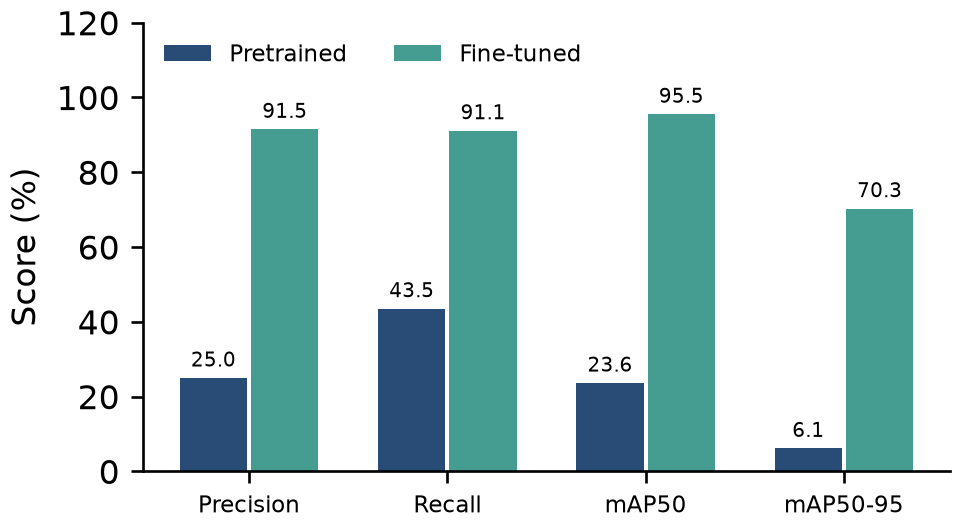

In [1]:
import matplotlib.pyplot as plt
scores = [[24.97, 43.51, 23.61, 6.14], [91.47, 91.1, 95.51, 70.26]]
fig, ax = plt.subplots(figsize=(4, 2.2), layout='constrained')
for row, offset, label, color in zip(scores, [-.18,.18], ['Pretrained','Fine-tuned'], ['#284C75','#459C91']):
    bars=ax.bar([i+offset for i in range(4)], row, .34, label=label, color=color)
    ax.bar_label(bars, fmt='%.1f', fontsize=6, padding=2)
ax.set_xticks(range(4), ['Precision','Recall','mAP50','mAP50-95'], fontsize=7)
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 120)
ax.legend(loc='upper left', ncols=2, fontsize=7, frameon=False)
plt.show()


## 훈련·검증 손실 곡선

출처는 classroom-person/results.csv이다. box·cls·L1 손실의 합을 검증 총손실로 정의했다. 검증 총손실은 38 epoch에서 1.48471로 최소였다. 기존 best.pt의 기록과 테스트 실행의 가중치 SHA-256이 일치한다.

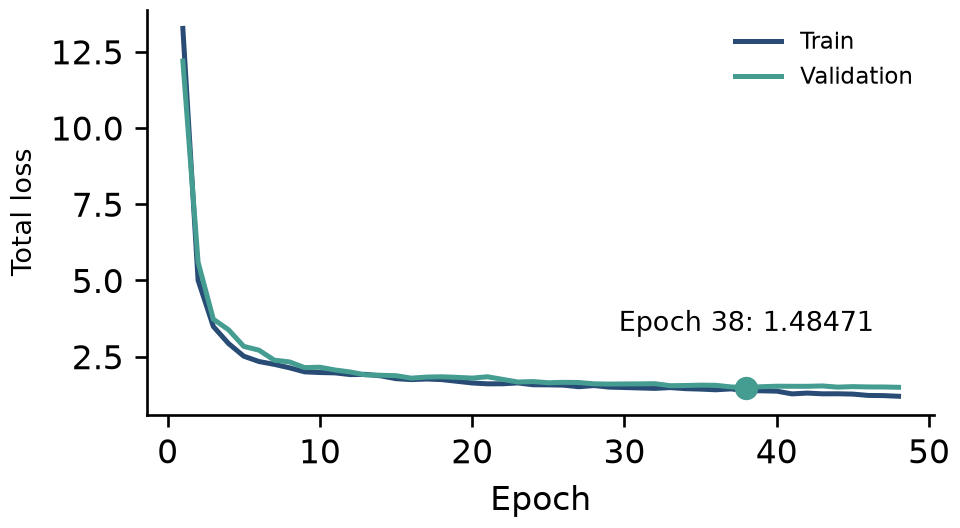

In [2]:
epochs = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]
losses = {'train': [13.26453, 5.00365, 3.48878, 2.92812, 2.51376, 2.33855, 2.2457, 2.13321, 1.99922, 1.97712, 1.96607, 1.90907, 1.91814, 1.868, 1.7761, 1.74518, 1.76478, 1.74568, 1.69007, 1.6353, 1.60688, 1.60833, 1.63634, 1.57629, 1.5733, 1.56286, 1.51156, 1.55044, 1.49885, 1.48599, 1.47109, 1.45742, 1.4838, 1.44864, 1.43376, 1.41173, 1.44044, 1.38051, 1.37783, 1.36675, 1.27699, 1.30346, 1.27934, 1.28044, 1.27003, 1.22657, 1.22081, 1.19878], 'val': [12.19403, 5.59767, 3.72792, 3.38029, 2.83504, 2.70962, 2.38352, 2.32576, 2.13856, 2.15119, 2.06059, 1.99455, 1.89927, 1.88796, 1.87365, 1.79304, 1.82886, 1.8376, 1.81976, 1.79472, 1.83779, 1.75294, 1.66682, 1.68103, 1.64254, 1.65585, 1.65013, 1.60702, 1.59893, 1.6033, 1.60529, 1.61161, 1.54579, 1.55178, 1.56405, 1.55877, 1.50483, 1.48471, 1.51188, 1.52854, 1.52593, 1.5256, 1.53756, 1.49845, 1.51542, 1.5049, 1.50344, 1.49315]}
fig, ax = plt.subplots(figsize=(4, 2.2), layout='constrained')
ax.plot(epochs, losses['train'], color='#284C75', label='Train')
ax.plot(epochs, losses['val'], color='#459C91', label='Validation')
best=min(range(len(epochs)), key=losses['val'].__getitem__)
ax.scatter(epochs[best], losses['val'][best], color='#459C91', zorder=3)
ax.annotate(f'Epoch {epochs[best]}: {losses["val"][best]:.5f}', (epochs[best],losses['val'][best]),
            xytext=(0,17), textcoords='offset points', ha='center', fontsize=8)
ax.legend(loc='upper right', fontsize=7, frameon=False)
ax.set_xlabel('Epoch')
ax.set_ylabel('Total loss', fontsize=8)
plt.show()


## 검증 비교와 체크리스트

동일한 사람 탐지 기준의 검증 mAP50–95는 7.17% → 71.08%. 분할 간 동일 파일 해시와 내보내기 전 파일명 중복은 0건이었다. 세 분할에 공통으로 나타나는 파일명 날짜·접두사가 있으나 개인·세션 식별자가 없어 집단 분리는 입증되지 않았다. 이번 보고서는 기록된 검증 총손실의 최솟값으로 가중치를 다시 선정했다. 원래 학습 도구가 mAP50–95로 저장한 best.pt와 같은 38 epoch 가중치였다.